
Lineage1: 25678 клеток
AB_CD14      | r =  0.176 | p = 3.49e-178
AB_CD16      | r = -0.058 | p = 1.64e-20
AB_CX3CR1    | r =  0.064 | p = 9.96e-25
AB_CD163     | r =  0.089 | p = 1.25e-46
AB_HLA-DR    | r =  0.227 | p = 1.92e-298
AB_CD64      | r =  0.079 | p = 1.29e-36
AB_CD83      | r = -0.104 | p = 1.05e-62
AB_SIGLEC1   | r = -0.008 | p = 1.73e-01


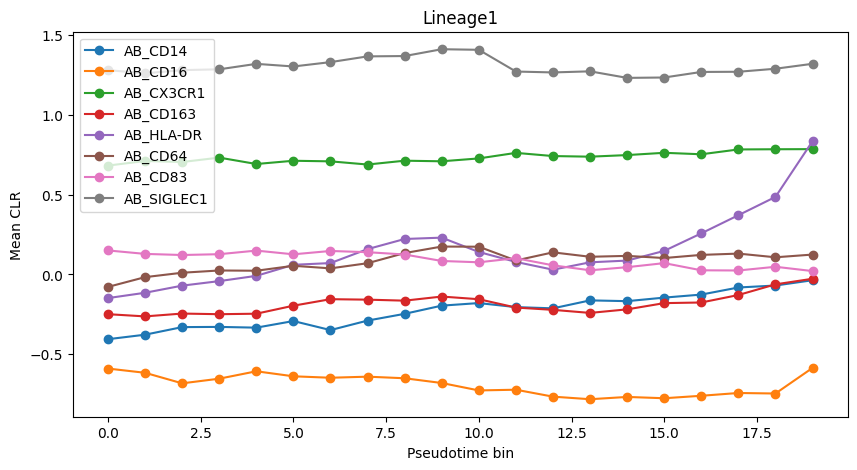


Lineage2: 19041 клеток
AB_CD14      | r =  0.013 | p = 7.73e-02
AB_CD16      | r =  0.326 | p = 0.00e+00
AB_CX3CR1    | r =  0.253 | p = 6.19e-276
AB_CD163     | r =  0.107 | p = 9.25e-50
AB_HLA-DR    | r =  0.434 | p = 0.00e+00
AB_CD64      | r = -0.096 | p = 6.61e-40
AB_CD83      | r = -0.065 | p = 3.86e-19
AB_SIGLEC1   | r = -0.020 | p = 5.74e-03


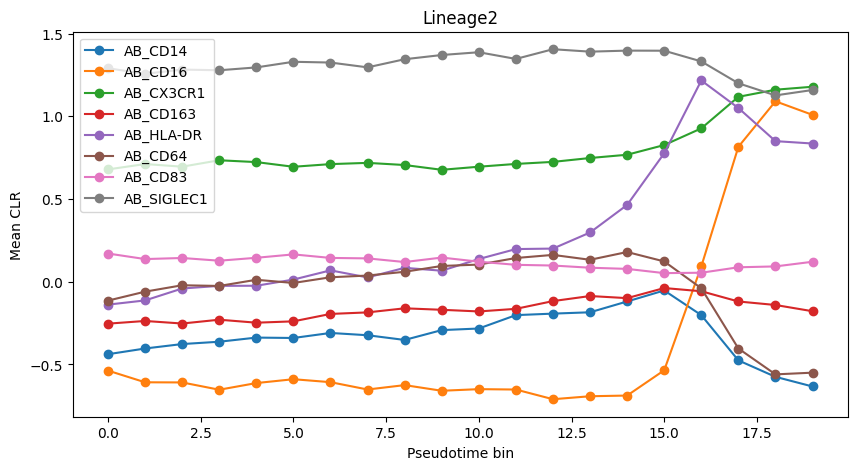

In [2]:
import pandas as pd
import numpy as np
import scanpy as sc
from scipy.stats import spearmanr
from scipy.sparse import issparse
import matplotlib.pyplot as plt

adata = sc.read_h5ad('../data_bio/covid_mono_prot.h5ad')
df_pt = pd.read_csv('../data_bio/slingshot_pseudotime_all_lineages.csv', index_col='cell_id')

proteins = ['AB_CD14', 'AB_CD16', 'AB_CX3CR1', 'AB_CD163',
            'AB_HLA-DR', 'AB_CD64', 'AB_CD83', 'AB_SIGLEC1']
valid_proteins = [p for p in proteins if p in adata.var_names]

X = adata.layers['raw']
X = X.toarray() if issparse(X) else np.asarray(X)
logX = np.log1p(X)
clr = logX - logX.mean(axis=1, keepdims=True)
df_all = pd.DataFrame(clr, columns=adata.var_names, index=adata.obs_names)

for lin in ['Lineage1', 'Lineage2']:
    d = df_all[valid_proteins].join(df_pt[[lin]], how='inner').dropna(subset=[lin])
    print(f"\n{lin}: {len(d)} клеток")
    for prot in valid_proteins:
        r, p = spearmanr(d[lin], d[prot])
        print(f"{prot:12s} | r = {r:6.3f} | p = {p:.2e}")

    d['bin'] = pd.qcut(d[lin], q=20, labels=False)
    d.groupby('bin')[valid_proteins].mean().plot(figsize=(10, 5), marker='o', title=lin)
    plt.xlabel('Pseudotime bin')
    plt.ylabel('Mean CLR')
    plt.show()

9921 full_clustering
CD14_mono         5806
CD16_mono         3281
C1_CD16_mono       834
CD83_CD14_mono       0
Mono_prolif          0
Name: count, dtype: int64
AB_CD14      | r = -0.152 | p = 2.56e-52
AB_CD16      | r =  0.539 | p = 0.00e+00
AB_CX3CR1    | r =  0.377 | p = 0.00e+00
AB_CD163     | r =  0.023 | p = 2.45e-02
AB_HLA-DR    | r =  0.415 | p = 0.00e+00
AB_CD64      | r = -0.306 | p = 9.24e-214
AB_CD83      | r = -0.026 | p = 1.10e-02
AB_SIGLEC1   | r = -0.160 | p = 7.17e-58


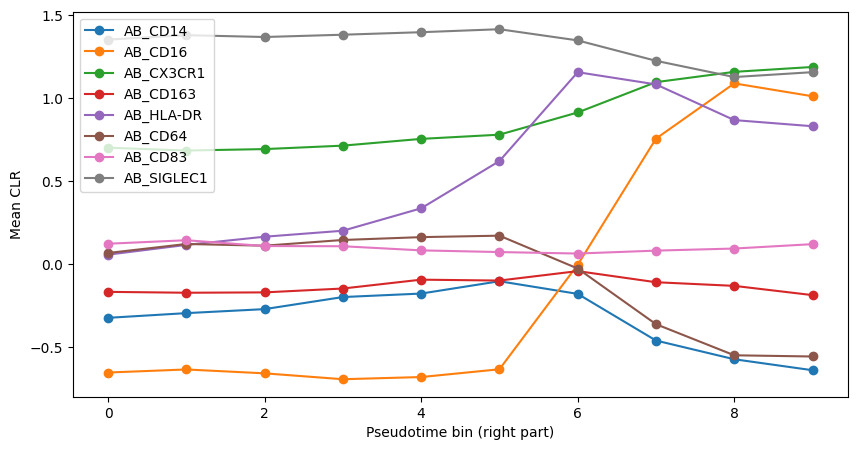

C1_CD16_mono 863 {'AB_CD16': np.float64(0.546), 'AB_CD14': np.float64(-0.203), 'AB_CX3CR1': np.float64(0.336)}
CD16_mono 3469 {'AB_CD16': np.float64(0.381), 'AB_CD14': np.float64(-0.258), 'AB_CX3CR1': np.float64(0.2)}


In [4]:
lin = 'Lineage2'
d = df_all[valid_proteins].join(df_pt[[lin]], how='inner').dropna(subset=[lin])
d = d.join(adata.obs['full_clustering'])

d = d[d['full_clustering'].isin(['CD14_mono', 'C1_CD16_mono', 'CD16_mono'])]
d['bin'] = pd.qcut(d[lin], q=20, labels=False)

cut = d.loc[d['full_clustering'].isin(['C1_CD16_mono', 'CD16_mono']), lin].quantile(0.05)
dr = d[d[lin] >= cut]
print(len(dr), dr['full_clustering'].value_counts())

for prot in valid_proteins:
    r, p = spearmanr(dr[lin], dr[prot])
    print(f"{prot:12s} | r = {r:6.3f} | p = {p:.2e}")

dr = dr.copy()
dr['bin'] = pd.qcut(dr[lin], q=10, labels=False)
dr.groupby('bin')[valid_proteins].mean().plot(figsize=(10, 5), marker='o')
plt.xlabel('Pseudotime bin (right part)')
plt.ylabel('Mean CLR')
plt.show()

for cl in ['C1_CD16_mono', 'CD16_mono']:
    s = d[d['full_clustering'] == cl]
    print(cl, len(s), {p: round(spearmanr(s[lin], s[p])[0], 3) for p in ['AB_CD16', 'AB_CD14', 'AB_CX3CR1']})